### IPD441 - Visión por Computador
# Clase 15: Image Morphing

Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Neural style transfer

La transferencia de estilo neuronal es un proceso que busca generar una imagen que conserve el "contenido" de una imagen base pero adopte el "estilo" de otra imagen, generalmente artística. Este método se basa en el descenso de gradiente para optimizar una función de pérdida que consta de tres componentes: "pérdida de estilo" (style loss), "pérdida de contenido" (content loss) y "pérdida de variación total" (total variation loss).

<div align="center">
    <img src="img/neural_style_transfer.jpg" alt="" width="90%" align="center" />
</div>

In [1]:
import matplotlib.pyplot as plt

In [2]:
def plot_images(images):
    total_images = len(images)
    if total_images < 2:
        plt.figure(figsize=(4, 4))
        plt.imshow(images[0])
        plt.axis('off')
    else:
        fig, axes = plt.subplots(1, 
                                 total_images, 
                                 figsize=(4*total_images, 4))
        for i in range(total_images):
            axes[i].imshow(images[i])
            axes[i].axis('off')
        plt.tight_layout()
    plt.show()

In [3]:
from style import *

## Contenido y Referencia de Estilo

Se selecciona una imagen base (contenido) que servirá como la estructura principal de la nueva imagen generada y se elige una segunda imagen (referencia de estilo) que posea el estilo que se quiere aplicar a la imagen base.

In [4]:
content_img = load_image('test/gioconda.jpg')
style_img = load_image('test/vangogh.jpeg')    

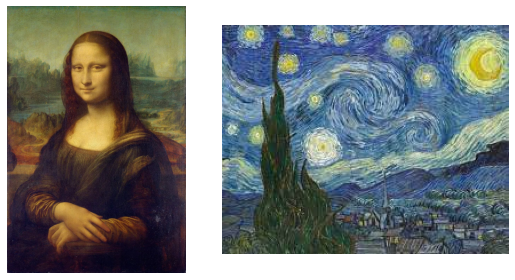

In [5]:
plot_images([convert(content_img), convert(style_img)])

## Extracción de características

Se utiliza una CNN preentrenada para extraer características tanto de la imagen base como de la imagen de referencia de estilo. Las capas de la red convolucional capturan características a diferentes niveles de abstracción.

## Matrices de Gram 

Se calculan las matrices de Gram para las representaciones de las capas seleccionadas en la red convolucional tanto para la imagen base como para la imagen de referencia de estilo. Estas matrices permiten capturar las correlaciones estadísticas entre las características extraídas por la red.

<div align="center">
    <img src="img/gram.png" alt="" width="70%" align="center" />
</div>

## Optimización y Descenso de Gradiente

Se utiliza un algoritmo de descenso de gradiente para modificar la imagen base de manera iterativa y minimizar la pérdida total.

In [6]:
def transfer_style(content_img, style_img, n_iter = 500, show_each_iter = 100, 
                   save = False, preserve_color = "False"):
    content_tensor = itot(content_img).to(device)
    style_tensor = itot(style_img).to(device)
    g = initial(content_tensor, init_image='random')
    g = g.to(device).requires_grad_(True)
    stylize(content_tensor, style_tensor, g, NUM_ITER = n_iter, SAVE = save,
            SHOW_ITER = show_each_iter, PRESERVE_COLOR = preserve_color)


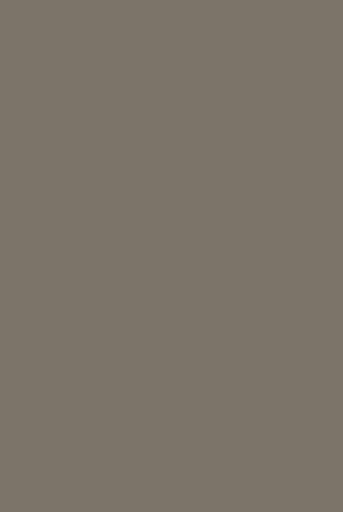
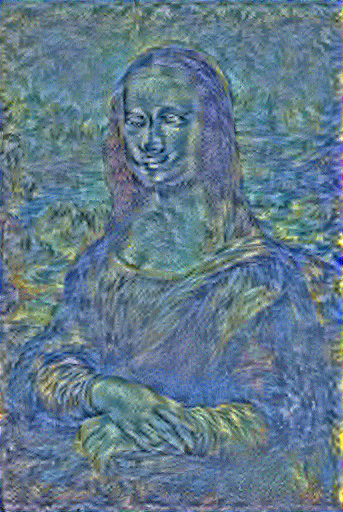
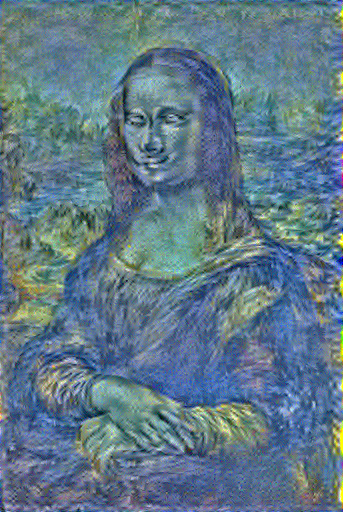
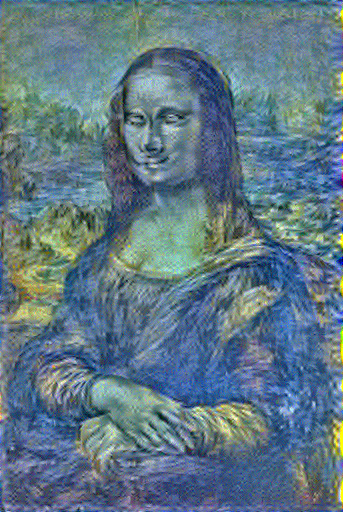
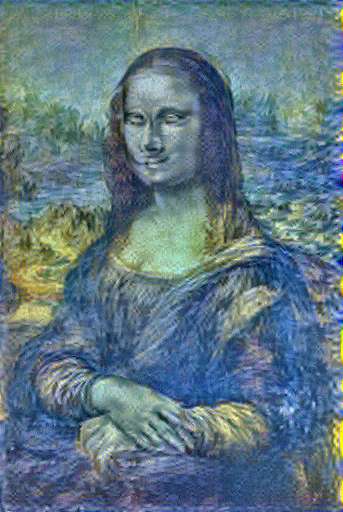

In [7]:
transfer_style(content_img, style_img, n_iter = 500, show_each_iter = 100)

# Image morphing

El "image morphing" (o morfización de imágenes) es un proceso mediante el cual se crea una transición suave y gradual entre dos imágenes diferentes. El objetivo es transformar una imagen inicial en otra de manera continua, generando una secuencia de imágenes intermedias que capturan la transición entre las dos imágenes originales.

<div align="center">
    <img src="img/morph.jpeg" alt="" width="100%" align="center" />
</div>

# Differentiable Morphing

Es un método que puede transformar dos imágenes sin necesidad de puntos de referencia, por medio de técnicas de deformación diferenciable.

Supongamos que queremos producir una imagen a partir de otra de manera que utilicemos la mayor cantidad de información útil posible, de modo que si dos imágenes dadas comparten alguna similitud entre ellas, hacemos uso de estas similitudes.

<div align="center">
    <img src="img/toy_example.jpg" alt="" width="30%" align="center" />
</div>

## Fórmula

<div align="center">
    <img src="img/formula.jpg" alt="" width="50%" align="center" />
</div>

"<tt>Mult map</tt>" elimina partes innecesarias de una imagen y cambia el equilibrio de color, "<tt>Add map</tt>" crea nuevos colores que no están presentes en la imagen original y "<tt>Warp map</tt>" distorsiona una imagen de alguna manera para reproducir el cambio, la rotación y la escala de los objetos. La operación <tt>W</tt> se usa para tareas de estimación de flujo óptico.

<div align="center">
    <img src="img/transition.jpg" alt="" width="50%" align="center" />
</div>

In [ ]:
%cd DiffMorph

In [2]:
# !pip install tensorflow-addons

In [ ]:
from morph import *

In [12]:
produce_maps('../test/woman1.jpg', '../test/woman2.jpg', train_epochs = 1000, output_name = "saved/women.npy")

Epoch 1000, Loss: 0.011931188404560089: 100%|██████████| 1000/1000 [18:05<00:00,  1.09s/it]


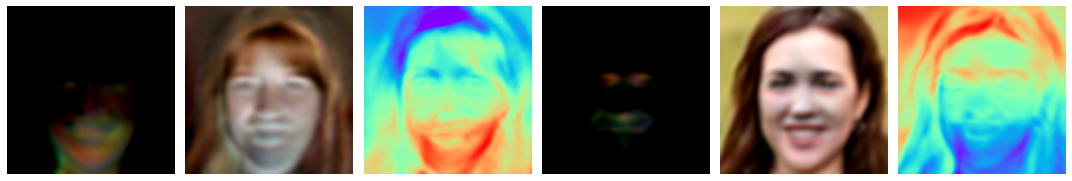

In [13]:
plot_maps('saved/women.npy')

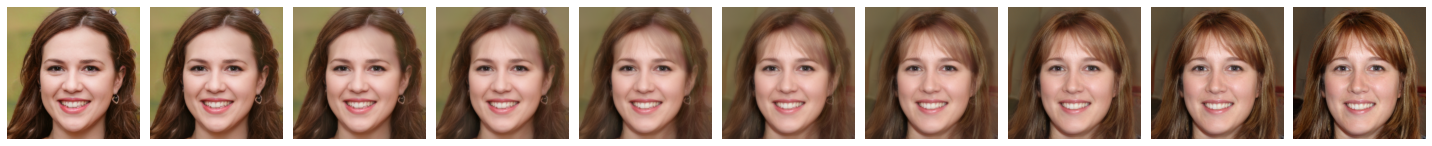

In [14]:
morphing('../test/woman1.jpg', '../test/woman2.jpg', 'saved/women.npy', steps=100)

In [4]:
produce_maps('../test/jennie.png', '../test/rih.png', train_epochs = 1000, output_name = "saved/celebs.npy")

Epoch 1000, Loss: 0.018178440630435944: 100%|██████████| 1000/1000 [18:38<00:00,  1.12s/it]


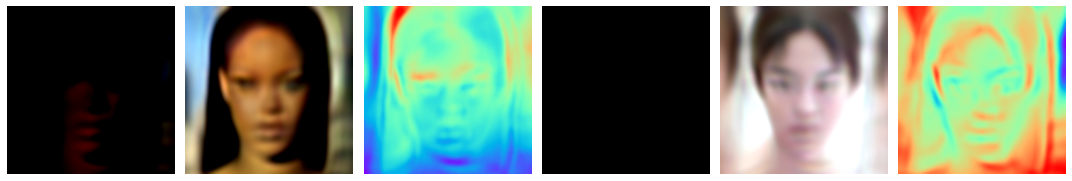

In [5]:
plot_maps('saved/celebs.npy')

# El efecto fantasma 

El efecto fantasma se debe a la desalineación de dos caras, en particular, a la desalineación de dos conjuntos de rasgos faciales importantes, como los ojos, la nariz y la boca. Por lo tanto, para alinear la forma entre la salida, debemos asegurarnos de que las características importantes puedan coincidir consistentemente en todos los fotogramas.

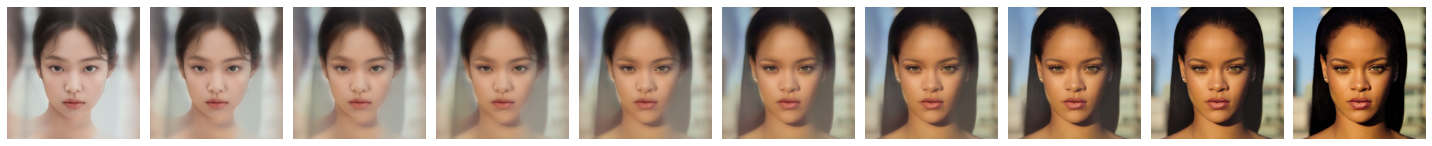

In [6]:
morphing('../test/jennie.png', '../test/rih.png', 'saved/celebs.npy', steps=100)

# Face Morphing con puntos de referencia

Los "keypoints" o puntos de referencia son puntos específicos identificados en una imagen para describir características particulares de un objeto o región de interés. En el caso de Face Morphing, los keypoints se utilizan para identificar y localizar características faciales específicas como los ojos, la nariz, la boca, las orejas, etc. Cada uno de estos puntos de referencia es crucial para describir la geometría y la estructura del rostro en la imagen.

# Formulación matemática

El objetivo es tranformar una imagen $I_0$ en $I_1$, de forma suave, con frames intermedios lo más realistas posibles. Podemos ver los resultados como una secuencia de fotogramas. Dadas dos imágenes de entrada I₀ e I₁, en cada marca de tiempo t entre 0 y 1, cada píxel (x, y) en el cuadro transformado se puede interpolar de la siguiente manera:

$$ M_t(x,y) = (1-t) * I_0(x,y) + t * I_1(x,y) $$


Cuando t es igual a 0, el cuadro transformado es exactamente la Imagen I₀, cuando t es igual a 1, el cuadro transformado es exactamente la Imagen I₁ y el cuadro en t es la combinación de dos imágenes en el momento t. Esto se llama "difusión cruzada", pero inevitablemente dejará los efectos "fantasma" si las dos caras no están perfectamente alineadas.

# Dlib

Dlib es una implementación del artículo Alineación de caras en un milisegundo con un conjunto de árboles de regresión de Kazemi y Sullivan (2014), que entrega la ubicación estimada de 68 pares de coordenadas (x, y) que representan regiones destacadas de la cara, incluidos los ojos, las cejas, la nariz, la boca y la mandíbula.

<div align="center">
    <img src="img/facial_landmarks_68markup.jpg" alt="" width="30%" align="center" />
</div>

In [1]:
import cv2
import skimage
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
import dlib

In [3]:
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor('shape_predictor_68_face_landmarks.dat')

In [4]:
def keypoints(path, detector, predictor):
    img = dlib.load_rgb_image(path)
    imTemp = img.copy()
    rect = detector(img)[0]
    sp = predictor(img, rect)
    landmarks = np.array([[p.x, p.y] for p in sp.parts()])
    for point in landmarks:
        cv2.circle(imTemp, point, 5, (0,255,0), -1)
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 3, 2)
    img = Image.open("img/facial_landmarks_68markup.jpg")
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 3, 3)
    plt.imshow(imTemp)
    plt.axis('off')
    plt.show()

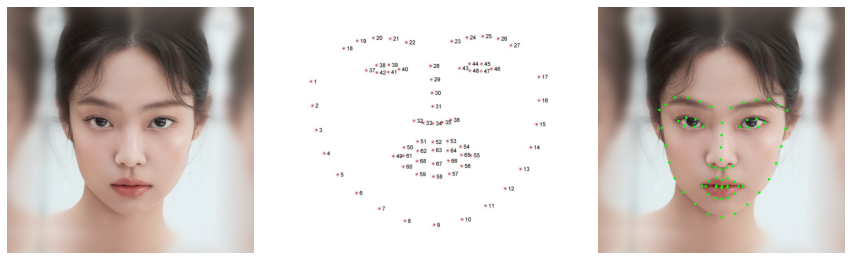

In [5]:
keypoints('test/jennie.png', detector, predictor)

In [6]:
mapa_facial = {'boca': [*range(48, 68)],
 'ceja_derecha': [*range(17, 22)],
 'ceja_izquierda': [*range(22, 27)],
 'ojo_derecho': [*range(36, 42)],
 'ojo_izquierdo': [*range(42, 48)],
 'nariz': [*range(27, 35)],
 'mandíbula': [*range(0, 17)],
 'rostro': [*range(0, 17), *range(26, 16, -1)]}

In [7]:
def matiz(image, channel, alpha):
    i=image.copy()
    i[:,channel]=i[:,channel]*alpha
    i[i>255]=255
    return i

In [8]:
def fake_points(path, zone, d, detector, predictor, channel, alpha):
    img = dlib.load_rgb_image(path)
    rect = detector(img)[0]
    landmarks = predictor(img, rect)
    imTemp = img.copy()
    for n in d[zone]:
        x=landmarks.part(n).x
        y=landmarks.part(n).y
        cv2.circle(imTemp, (x, y), 2, (0, 0, 255), -1)
    outline = np.array([[p.x, p.y] for p in landmarks.parts()])[d[zone]]
    Y, X = skimage.draw.polygon(outline[:,1], outline[:,0])
    cropped_img = img.copy()
    cropped_img[Y, X] = matiz(img[Y, X],channel,alpha)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(cropped_img)
    plt.axis('off')

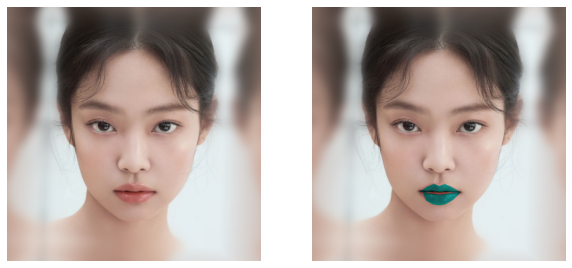

In [9]:
fake_points('test/jennie.png', 'boca', mapa_facial, detector, predictor, 0, 0.1)

In [10]:
def keypoints_for_all(images, detector, predictor):
    fig, axes = plt.subplots(1, len(images), figsize=(5*len(images), 5))
    for idx, path in enumerate(images):
        img = dlib.load_rgb_image(path)
        imTemp = img.copy()
        rect = detector(img)[0]
        sp = predictor(img, rect)
        landmarks = np.array([[p.x, p.y] for p in sp.parts()])
        for point in landmarks:
            cv2.circle(imTemp, point, 5, (0,255,0), -1)
        axes[idx].imshow(imTemp)
        axes[idx].axis('off')
    plt.show()

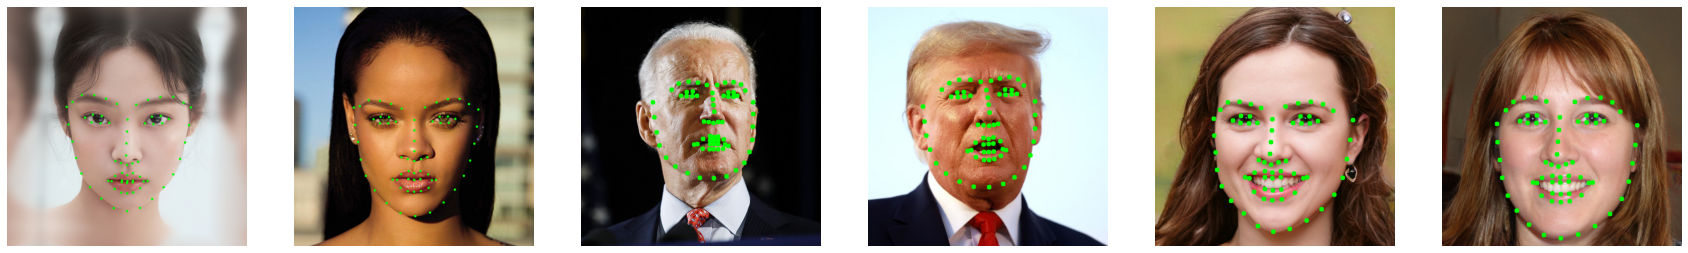

In [11]:
images = ['test/jennie.png','test/rih.png', 
          'test/Biden.jpg', 'test/Trump.jpg', 
          'test/woman1.jpg', 'test/woman2.jpg']
keypoints_for_all(images, detector, predictor)

## Convex Hull

Convex Hull es una técnica utilizada para encontrar el polígono convexo más pequeño que contiene un conjunto dado de puntos en el plano. El polígono convexo es el polígono con todos sus ángulos internos menores o iguales a 180 grados y, por lo tanto, no tiene "entrantes". En la extracción de rostros, los puntos de interés (por ejemplo, los bordes del rostro) se pueden utilizar como entrada para el algoritmo Convex Hull.

In [12]:
def face_extraction(path, detector, predictor):
    img = dlib.load_rgb_image(path)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = np.zeros_like(img_gray)
    faces = detector(img_gray)
    
    for face in faces:
        points = predictor(img_gray, face)
        points_list = []
        for n in range(0, 68):
            x = points.part(n).x
            y = points.part(n).y
            points_list+=[(x, y)]

        points = np.array(points_list, np.int32)
        convexhull = cv2.convexHull(points)
        cv2.fillConvexPoly(mask, convexhull, 255)
        face_image_1 = cv2.bitwise_and(img, img, mask=mask)
        
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(face_image_1)
    plt.axis('off')
    return convexhull, points_list

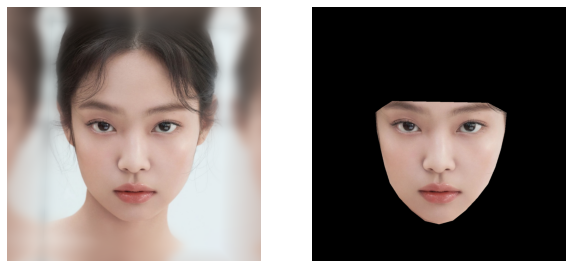

In [13]:
convexhull, points_list = face_extraction('test/jennie.png', detector, predictor)

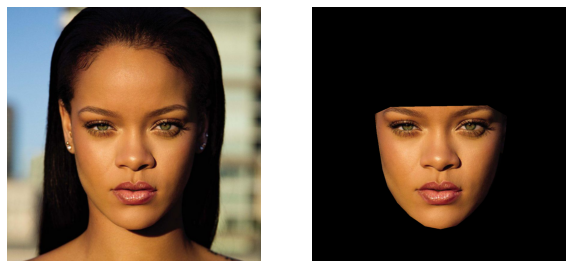

In [14]:
convexhull2, points_list2 = face_extraction('test/rih.png', detector, predictor)

In [15]:
def drawing_triangles(path, convexhull, points_list):
    img = dlib.load_rgb_image(path)
    rect = cv2.boundingRect(convexhull)
    subdiv = cv2.Subdiv2D(rect)
    subdiv.insert(points_list)
    triangles = subdiv.getTriangleList()
    triangles = np.array(triangles, dtype=np.int32)
    points = np.array(points_list, np.int32)
    triangles_id = []
    def index_nparray(nparray):
        index = None
        for num in nparray[0]:
            index = num
            break
        return index
    for t in triangles:
        pt1 = (t[0], t[1])
        pt2 = (t[2], t[3])
        pt3 = (t[4], t[5])

        cv2.line(img, pt1, pt2, (255, 0, 0), 2)
        cv2.line(img, pt2, pt3, (255, 0, 0), 2)
        cv2.line(img, pt1, pt3, (255, 0, 0), 2)
        
        id_pt1 = np.where((points == pt1).all(axis=1))
        id_pt1 = index_nparray(id_pt1)
        id_pt2 = np.where((points == pt2).all(axis=1))
        id_pt2 = index_nparray(id_pt2)
        id_pt3 = np.where((points == pt3).all(axis=1))
        id_pt3 = index_nparray(id_pt3)

        if id_pt1 is not None and id_pt2 is not None and id_pt3 is not None:
            triangle = [id_pt1, id_pt2, id_pt3]
            triangles_id.append(triangle)

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    return triangles_id

## Triangular Mesh

Una malla triangular es una red de triángulos conectados que se superpone a una imagen. Cada vértice de la malla está asociado con un punto en la imagen. Estos triángulos y sus vértices forman una estructura que permite representar y manipular la imagen de manera más flexible.

<div align="center">
    <img src="img/triangular-mesh.png" alt="" width="10%" align="center" />
</div>

## Triangulación de Delaunay

La triangulación de Delaunay proporciona triángulos que se pueden hacer en la imagen y que se pueden usar para hacer un polígono. En nuestro caso, el polígono es una cara y las regiones de la cara se dividen mediante triángulos.

<div align="center">
    <img src="img/triangulation.png" alt="" width="50%" align="center" />
</div>

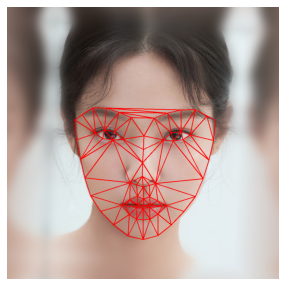

In [16]:
triangles_id = drawing_triangles('test/jennie.png', convexhull, points_list)

## Warping Triangular Mesh

"Warping" se refiere a la deformación de una imagen. Por lo tanto, "Warping Triangular Mesh" se refiere a una técnica en la que una malla triangular (triangular mesh) se utiliza para deformar o "warpear" una imagen. En esta técnica, los vértices de la malla triangular se pueden mover para deformar la imagen. La deformación se realiza interpolando los valores de los píxeles dentro de cada triángulo de la malla.

<div align="center">
    <img src="img/Warping_Triangular_Mesh.gif" alt="" width="80%" align="center" />
</div>

## Swap faces

"Swap faces" (intercambio de caras) es una técnica utilizada para intercambiar las caras de dos personas en una imagen. El proceso comienza con la detección de rostros en una imagen, seguido de la extracción de características faciales clave. Se genera una malla triangular que se ajusta a las caras detectadas, y se establece una correspondencia entre puntos clave para intercambiar las caras. Luego, se utiliza la técnica de "Warping" para deformar las regiones faciales, se realiza un blending para suavizar transiciones, y se ajusta el color antes de presentar la imagen con las caras intercambiadas al usuario.



In [17]:
def swap_faces(path1, path2, convexhull2, triangles_id, points_list, points_list2):
    img1 = dlib.load_rgb_image(path1)
    img2 = dlib.load_rgb_image(path2)
    img2_gray = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
    img2_new_face = np.zeros_like(img2, np.uint8)
    for triangle_index in triangles_id:
        tr1_pt1 = points_list[triangle_index[0]]
        tr1_pt2 = points_list[triangle_index[1]]
        tr1_pt3 = points_list[triangle_index[2]]
        triangle1 = np.array([tr1_pt1, tr1_pt2, tr1_pt3], np.int32)
        rect1 = cv2.boundingRect(triangle1)
        (x1, y1, w1, h1) = rect1
        cropped_triangle = img1[y1: y1 + h1, x1: x1 + w1]
        cropped_tr1_mask = np.zeros((h1, w1), np.uint8)
        points = np.array([[tr1_pt1[0] - x1, tr1_pt1[1] - y1],
                          [tr1_pt2[0] - x1, tr1_pt2[1] - y1],
                          [tr1_pt3[0] - x1, tr1_pt3[1] - y1]], np.int32)
        cv2.fillConvexPoly(cropped_tr1_mask, points, 255)
        cropped_triangle = cv2.bitwise_and(cropped_triangle, cropped_triangle,
                                           mask=cropped_tr1_mask)

        tr2_pt1 = points_list2[triangle_index[0]]
        tr2_pt2 = points_list2[triangle_index[1]]
        tr2_pt3 = points_list2[triangle_index[2]]
        triangle2 = np.array([tr2_pt1, tr2_pt2, tr2_pt3], np.int32)
        rect2 = cv2.boundingRect(triangle2)
        (x2, y2, w2, h2) = rect2
        cropped_triangle2 = img2[y2: y2 + h2, x2: x2 + w2]
        cropped_tr2_mask = np.zeros((h2, w2), np.uint8)
        points2 = np.array([[tr2_pt1[0] - x2, tr2_pt1[1] - y2],
                           [tr2_pt2[0] - x2, tr2_pt2[1] - y2],
                           [tr2_pt3[0] - x2, tr2_pt3[1] - y2]], np.int32)
        cv2.fillConvexPoly(cropped_tr2_mask, points2, 255)
        cropped_triangle2 = cv2.bitwise_and(cropped_triangle2, cropped_triangle2,
                                           mask=cropped_tr2_mask)

        points = np.float32(points)
        points2 = np.float32(points2)
        M = cv2.getAffineTransform(points, points2)
        warped_triangle = cv2.warpAffine(cropped_triangle, M, (w2, h2))
        warped_triangle = cv2.bitwise_and(warped_triangle, warped_triangle, mask=cropped_tr2_mask)

        img2_new_face_rect_area = img2_new_face[y2: y2 + h2, x2: x2 + w2]
        img2_new_face_rect_area_gray = cv2.cvtColor(img2_new_face_rect_area, cv2.COLOR_BGR2GRAY)

        _, mask_triangles_designed = cv2.threshold(img2_new_face_rect_area_gray, 1, 255, cv2.THRESH_BINARY_INV)
        warped_triangle = cv2.bitwise_and(warped_triangle, warped_triangle, mask=mask_triangles_designed)

        img2_new_face_rect_area = cv2.add(img2_new_face_rect_area, warped_triangle)
        img2_new_face[y2: y2 + h2, x2: x2 + w2] = img2_new_face_rect_area

    plt.figure(figsize=(20, 5))
    plt.subplot(1, 4, 1)
    plt.imshow(img2_new_face)
    plt.axis('off')
    
    img2_face_mask = np.zeros_like(img2_gray)
    img2_head_mask = cv2.fillConvexPoly(img2_face_mask, convexhull2, 255)
    img2_face_mask = cv2.bitwise_not(img2_head_mask)
    img2_noface = cv2.bitwise_and(img2, img2, mask=img2_face_mask)
    
    plt.subplot(1, 4, 2)
    plt.imshow(img2_noface)
    plt.axis('off')
    
    result = cv2.add(img2_noface, img2_new_face)
    
    plt.subplot(1, 4, 3)
    plt.imshow(result)
    plt.axis('off')
    
    (x3, y3, w3, h3) = cv2.boundingRect(convexhull2)
    center_face = (int((x3 + x3 + w3) / 2), int((y3 + y3 + h3) / 2))
    #removing the face from the img2
    img2_face_mask = np.zeros_like(img2_gray)
    img2_head_mask = cv2.fillConvexPoly(img2_face_mask, convexhull2, 255)
    img2_face_mask = cv2.bitwise_not(img2_head_mask)
    img2_noface = cv2.bitwise_and(img2, img2, mask=img2_face_mask)

    result = cv2.add(img2_noface, img2_new_face)

    #cloning face into the img2
    (x3, y3, w3, h3) = cv2.boundingRect(convexhull2)
    center_face2 = (int((x3 + x3 + w3) / 2), int((y3 + y3 + h3) / 2))
    seamlessclone = cv2.seamlessClone(result, img2, img2_head_mask, center_face2, cv2.MONOCHROME_TRANSFER)
    
    plt.subplot(1, 4, 4)
    plt.imshow(seamlessclone)
    plt.axis('off')

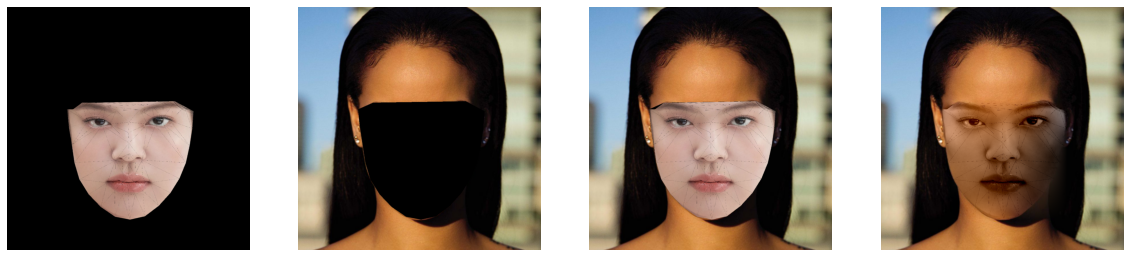

In [18]:
swap_faces('test/jennie.png', 'test/rih.png', convexhull2, triangles_id, points_list, points_list2)

# Face Morphing con puntos clave

In [ ]:
%cd Face-Morphing

In [20]:
from main import *

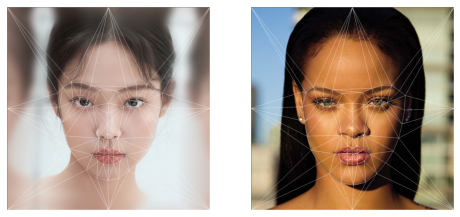

In [21]:
doMorphing("../test/jennie.png", "../test/rih.png", detector, predictor, frames=2)

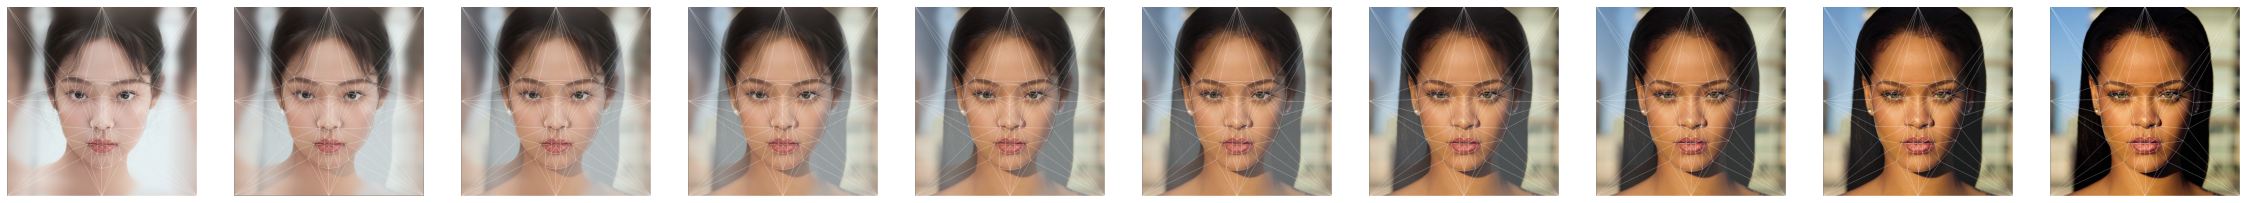

In [22]:
doMorphing("../test/jennie.png", "../test/rih.png", detector, predictor, frames=10)

# Ejemplo de Morphing Facial Interactivo

In [1]:
from interactive_morphing import *

In [2]:
initialize("test/jennie.png", "test/rih.png")

Imágenes cargadas con éxito.
Landmarks faciales detectados en ambas imágenes.
Inicialización completada. Se generaron 142 triángulos.
Usa 'start_interaction()' para iniciar la visualización interactiva.


True

In [3]:
start_interaction()

interactive(children=(FloatSlider(value=0.5, description='alpha', max=1.0, step=0.01), Output()), _dom_classes…